# Week 4: Probability distribution
**OPIM 5603: Statistics in Business Analytics - University of Connecticut**


In [ ]:
# Check R version
# Make sure it says R at the bottom
version
# Housekeeping
rm(list = ls())
# rm is to remove. ls stands for list (). This command is particularly useful when you want to clear your workspace to avoid conflicts, free up memory, or start fresh during an analysis.
# After running this command, all objects in your workspace will be deleted.

               _                           
platform       x86_64-pc-linux-gnu         
arch           x86_64                      
os             linux-gnu                   
system         x86_64, linux-gnu           
status                                     
major          4                           
minor          6.1                         
year           2026                        
month          06                          
day            24                          
svn rev        90187                       
language       R                           
version.string R version 4.6.1 (2026-06-24)
nickname       Happy Hop                   

# Slide 22: Discrete distribution
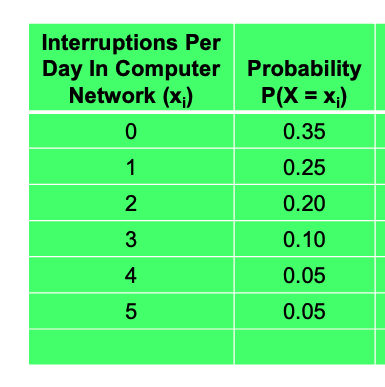

In [ ]:
# Setup the problem
num_inter <- c(0,1,2,3,4,5)  # c() creates an empty vector
prob_inter <- c(0.35, 0.25, 0.20, 0.10, 0.05, 0.05) # c() creates an empty vector

It is always good practice to make sure your numbers make sense!

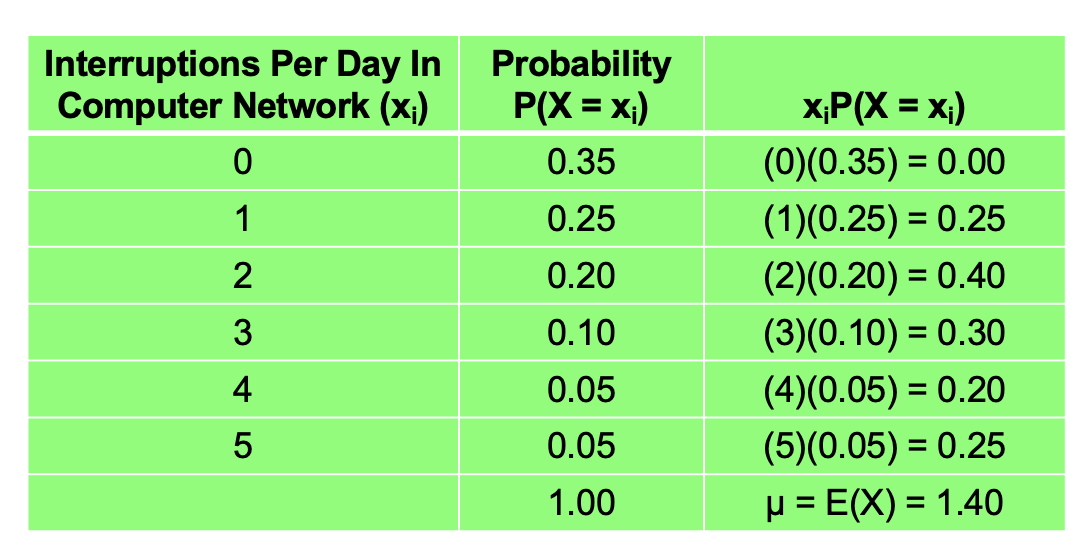

In [ ]:
# Calculate the summation of the prob. of interruptions and check it is equal to 1.
print(paste("Summation of the prob: ", sum(prob_inter)))

[1] "Summation of the prob:  1"


In [ ]:
# Calculate the expected valaue
ev_inter <- sum(num_inter * prob_inter)
print(paste("Expected Value = ", ev_inter))

[1] "Expected Value =  1.4"


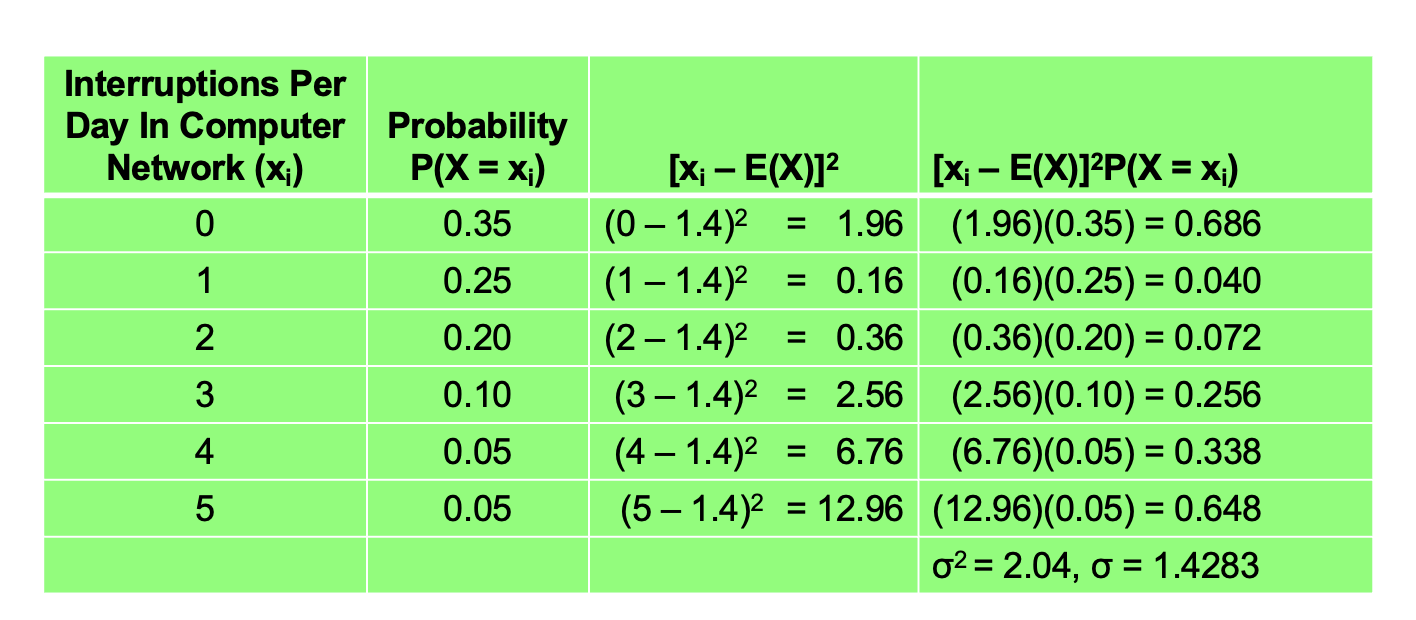

In [ ]:
# Calculate variance and standard deviation
# Step 1: Calculate the vector of values in Column 3
# var_inter_intermediate1
var_inter_intermediate1 <- (num_inter - ev_inter)^2

var_inter_intermediate1


[1]  1.96  0.16  0.36  2.56  6.76 12.96

In [ ]:
# Step 2: Calculate the vector of values in Column 4
# var_inter_intermediate2

var_inter_intermediate2 <- var_inter_intermediate1 * prob_inter

var_inter_intermediate2

[1] 0.686 0.040 0.072 0.256 0.338 0.648

In [ ]:
# Step 3: Calculate variance by summing up all the values in Column 4
# var_inter
var_inter <- sum(var_inter_intermediate2)

var_inter

[1] 2.04

In [ ]:
# Step 4: Calculate the standard deviation
#sd_inter
sd_inter <- sqrt(var_inter)

sd_inter

[1] 1.428286

## Practice Problem 1
Compute the mean and variance of the following discrete probability distribution.

$x$ | $P(x)$
---| ----
2|0.500
8|0.300
10|0.200

*Note how probabilities sum to 1, and that values don't need to be in order from 0, 1, 2...n*

Answer: $\mu = 5.4$ and $\sigma^2 =12.04$  Try this on your own using R!

What if I am interested in the $E(3X)$ and Var(3X)?

In [ ]:
num_inter <- c(2,8,10)
prob_inter <- c(0.500, 0.300, 0.200)

In [ ]:
# For 𝐸(𝑋) and 𝑉𝑎𝑟(𝑋)

# Calculate the expected value
ev_inter <- sum(num_inter * prob_inter)
print(paste("Expected Value = ", ev_inter))

# Calculate the variance
var_inter_intermediate1 <- (num_inter - ev_inter)^2
var_inter_intermediate2 <- var_inter_intermediate1 * prob_inter
var_inter <- sum(var_inter_intermediate2)
print(paste("Variance = ", var_inter))

[1] "Expected Value =  5.4"
[1] "Variance =  12.04"


In [ ]:
# For 𝐸(3𝑋) and 𝑉𝑎𝑟(3𝑋)

# Calculate the expected value
ev_inter <- sum((3 * num_inter) * prob_inter)
print(paste("Expected Value =", ev_inter))

# Calculate the variance
var_inter_intermediate1 <- (3 * num_inter - ev_inter)^2
var_inter_intermediate2 <- var_inter_intermediate1 * prob_inter

var_inter <- sum(var_inter_intermediate2)
print(paste("Variance =", var_inter))


[1] "Expected Value = 16.2"
[1] "Variance = 108.36"


# Slide 34: Binomial distribution

Corporation X is buying 150 computers from DELL.  It is known that the motherboard used in the computers have probability 0.12 of having a certain defect.
1.
What is the probability that 10 computers will have the defect?

Let $X$ be the number of computers that will have the defect.  We will assume that $X$ is a binomial random variable with $n=150$ and $\pi = 0.12$.

Here we are looking for: $P(X=10)$:

In [ ]:
# Calculate the prob. that 10 computers will have the defect
dbinom(x = 10,size = 150, prob = 0.12)

[1] 0.01222945

2. What is the probability that no more than 25 computers will have the defect?

Here we are looking for P(X<=25).

In [ ]:
# Calculate the prob. that no more than 25 computers will have the defect
pbinom(q = 25,size = 150, prob = 0.12)

[1] 0.9654479

3. What is the probability that fewer than 25 but at least 20 computers will have the defect?  

We are looking for: $P(20 <= X < 25) = P(19 < X <= 24)$.

Good! Now I can write: $F(24) - F(19)$

In [ ]:
# Calculate the prob. that fewer than 25 but at least 20 computers will have the defect
# Use the pbinom() function

pbinom(q = 24,size = 150, prob = 0.12) - pbinom(q = 19,size = 150, prob = 0.12)

[1] 0.2871133

In [7]:
# An alternative way to calculate the same question with dbinom()

dbinom(24,size = 150, prob = 0.12) + dbinom(23,size = 150, prob = 0.12) + dbinom(22,size = 150, prob = 0.12) + dbinom(21,size = 150, prob = 0.12) + dbinom(20,size = 150, prob = 0.12)

[1] 0.2871133

4. How many computers does Corporation X expect to have this defect? What is the standard deviation of the number of computers that have this defect?

In [ ]:
# Calculate E(X)
e_X <- 150*0.12

e_X

[1] 18

In [ ]:
# Calculate sd(X)
sd_X <- sqrt(150*0.12*(1-0.12))

sd_X

[1] 3.97995

5. Corporation X is reconsidering their decision to purchase the computers.  They only want to make the purchase if the probability of having more than 22 computers with the defect is less than 0.2.  Will the purchase be made?

We are interested in checking if $P(X   22) = 1-P(X 22) < .2.$

In [ ]:
# Calculate the prob. of more than 22 computers with defect
1 - pbinom(q = 22, size = 150, prob = 0.2)

[1] 0.9409996

The prob. is less than .2 and the purchase will be made.

6. Suppose that you are in charge of purchasing the computers, and you want to assure the president of Corporation X that this is a good purchase.  Your goal is to tell her “I am at least 90% sure that there will be at most K defective motherboards.” Of course, the lower K is, the better.  What is the lowest value of K that you can make this claim for? (K <= 30)

K s.t. P(X <= K) >= 90%

In [ ]:
# Calulate the lowest value of K
qbinom(0.9, 150, 0.12)
#binom( p = , size = , prob = )

[1] 23

## Practice Problem 2
You are placing a sensor in a home that detects power quality faults. Power quality faults happen in 1 in every 100 homes. What's the probability of finding at least 1 home with a fault if you install 500 sensors?

Hint: use pbinom()!
Answer: 0.993429516957585

In [ ]:
1- pbinom(0, 500, 0.01)

[1] 0.9934295

## Practice Problem 3
Assume you flip a fair coin 100 times. What is the number N that, 90% of the time, the number of heads is less than or equal to N?
Hint: Use the quantile function.
Answer: 56

In [ ]:
qbinom(0.9, 100, 0.5)

[1] 56

# Slide 40: Poisson distribution

The IT department at Corporation X maintains the website for the company.  Past experience indicates that during working hours, the average time between successive complaints on their website is 20 minutes.  If we model the number of complaints received in given work day as a Poisson distribution:

1. What is the average number of complaints received in an eight-hour work day?

Let X = number of complaints in a given work day

Let's models X as a Poisson distribution with lambda = 8*3 = 24!
(assume 8 hour work day)

In [ ]:
# Compute the expectation of number of complaints
# E(X) = lambda
lambda = 8 * 3

2. In an eight-hour work day, what is the probability that the IT department will receive fewer than 20 complaints?

We are interested in the prob. as follows,

P( X < 20 ) = P(X <= 19) = P(X <= 19.25).

In [ ]:
# Calculate the prob. that X is less than 20
ppois(q = 19, lambda = 24)

[1] 0.1802605

3. The Friday before each holiday, the IT department responds to complaints only for the first six hours of the day.  What is the probability that the IT department will receive fewer than 20 complaints in a six-hour day?

Let M = # complaints in six hours

In [ ]:
# Calculate the new expected number of complaints
new_lambda = 3*6

new_lambda

[1] 18

We are interested in P(M<20)

In [ ]:
# Calculat the prob. that M is less than 20
ppois(q = 19, lambda = 18)

[1] 0.6509161

## Practice Problem 4
Assume a a ball from the driving range, next door lands in your yard at an average rate of 3 balls per hour during the day. What is the probability that 2 or fewer golf balls will land in your yard during one hour? Answer: 0.4232

In [ ]:
# the prob. that 2 or less during 1 hour
# P(X<2)
ppois(q = 2, lambda = 3)

[1] 0.4231901

#<center><u>Reference: Probability Distributions in R</b></center>

|Distribution|Parameters|Density|Cumulated Probability Distribution(p)|Quantiles(q)|Random generator(r)
|---|---|---|---|---|---|
Binomial Distribution | $\checkmark$ Vector or single value to be evaluated: **x**<br> $\checkmark$ Number of trials:size<br> $\checkmark$ Probability of success: **prob**<br>$\checkmark$ Starting from lowertail (or not):lower.tail<br>$\checkmark$ Vector or single value of quantiles: **q**<br>$\checkmark$ Vector or single value of probabilities: **p**<br>$\checkmark$ Number of observations: **n**| dbinom(x,size,prob) P(X = x) | pbinom(q, size,prob, lower.tail= TRUE) F(x) = P(X <=x) | qbinom(p, size, prob, lower.tail =TRUE) |rbinom(n, size,prob) |
Poisson Distribution | $\checkmark$ Vector or single value to be evaluated:<b>x</b> <br>$\checkmark$ Poisson parameter:**lambda** <br>$\checkmark$Starting from lower tail (or not):**lower.tail** <br>$\checkmark$ Vector or single value of quantiles: **q** <br>$\checkmark$ Vector or single value of probabilities: **p**<br>$\checkmark$ Number of observations:<b>n</b>|dpois(x, lambda) |ppois(q,lambda,lower.tail =TRUE) | qpois(p,lambda,lower.tail =TRUE) | rpois(n, lambda) |
Normal Distribution | $\checkmark$ Vector or single value to be evaluated: <b>x</b> <br> $\checkmark$ Mean parameter: <b>mean</b>  <br> $\checkmark$ Standard deviation parameter: <b>sd</b> <br> $\checkmark$ Starting from lower tail (or not): <b>lower.tail</b> <br>$\checkmark$ Vector or single value of quantiles: <b>q</b> <br> $\checkmark$ Vector or single value of probabilities: <b>p</b> <br> $\checkmark$ Number of observations: <b>n</b>| dnorm(x, mean = 0, sd = 1) | pnor(q, mean = 0, sd = 1, lower.tail = TRUE) | qnorm(p, mean = 0, sd = 1, lower.tail = TRUE) | rnorm(n, mean = 0, sd = 1) |
Exponential Distribution | $\checkmark$ Vector or single value to be evaluated: <b> x </b> <br> $\checkmark$ Parameter: <b>rate (𝝺) </b> <br> $\checkmark$ Starting from lower tail (or not): <b>lower.tail</b> <br> $\checkmark$ Vector or single value of quantiles: <b>q</b> <br> $\checkmark$ Vector or single value of probabilities: <b>p</b> <br> $\checkmark$ Number of observations: <b>n</b> | dexp(x, rate = 1) | pexp(q, rate = 1, lower.tail = TRUE) | qexp(p, rate = 1, lower.tail = TRUE) | rexp(n, rate = 1) |
Uniform Distribution | $\checkmark$ Vector or single value to be evaluated: <b>x</b> <br> $\checkmark$ Minimum interval value: <b>min</b> <br> $\checkmark$ Maximum interval value: <b>max</b> <br> $\checkmark$ Starting from lower tail(or not): <b>lower.tail</b><br> $\checkmark$ Vector or single value of quantiles: <b>q</b> <br> $\checkmark$ Vector or single value of probabilities:<b>p</b><br>$\checkmark$ Number of observations: <b>n</b> |dunif(x,min= 0,max = 1) | punif(q, min= 0, max = 1,lower.tail = TRUE) | qunif(p, min=0, max = 1,lower.tail = TRUE) | runif(n, min= 0,max = 1)|

